# 02 - Modeling
## Step 1 - Baselines
- Goal: set the bar that XGBoost/LightGBM must beat. 
    - Two baselines: 
        - (1) always predict the average strength
        - (2) linear regression.

- Only `dev.csv` is used here. `test.csv` stays untouched until the very end.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

from src.evaluate import regression_metrics
from src.features import DEV_PATH, FEATURES, TARGET

dev = pd.read_csv(DEV_PATH)
X, y, groups = dev[FEATURES], dev[TARGET], dev["recipe_id"]
print("dev->shape:", dev.shape," | X->shape:", X.shape, " | y->shape:", y.shape, " | groups->shape:", groups.shape)

dev->shape: (799, 10)  | X->shape: (799, 8)  | y->shape: (799,)  | groups->shape: (799,)


In [2]:
# 5-fold CV where each recipe stays inside one fold (same leakage rule as the dev/test split)
gkf = GroupKFold(n_splits=5)
rows = []
for fold, (tr, va) in enumerate(gkf.split(X, y, groups), start=1):
    y_tr, y_va = y.iloc[tr], y.iloc[va]
    preds = {
        "mean_predictor": np.full(len(va), y_tr.mean()),
        "linear_regression": LinearRegression().fit(X.iloc[tr], y_tr).predict(X.iloc[va]),
    }
    for name, p in preds.items():
        rows.append({"model": name, "fold": fold, **regression_metrics(y_va, p)})
cv = pd.DataFrame(rows)
cv.round(2)

,model,fold,rmse,mae,r2
0,mean_predictor,1,15.19,12.10,-0.00
1,linear_regression,1,10.04,7.87,0.56
2,mean_predictor,2,15.87,12.77,-0.00
3,linear_regression,2,10.36,8.30,0.57
4,mean_predictor,3,16.63,13.34,-0.00
5,linear_regression,3,11.45,9.13,0.53
6,mean_predictor,4,14.82,12.13,-0.01
7,linear_regression,4,9.25,7.41,0.61
8,mean_predictor,5,16.44,13.67,-0.00
9,linear_regression,5,10.56,8.44,0.59


In [3]:
# mean and spread across the 5 folds
cv.groupby("model")[["rmse", "mae", "r2"]].agg(["mean", "std"]).round(2)

rmse          mae          r2      
                    mean   std   mean   std  mean   std
model                                                  
linear_regression  10.33  0.80   8.23  0.65  0.57  0.03
mean_predictor     15.79  0.78  12.80  0.70 -0.00  0.00

## Step 2 - A fairer linear baseline
- Linear regression can only draw straight lines, but age gains strength along a curve. Before comparing with XGBoost, give the linear model two domain-driven features so the comparison is fair: `log_age` and `water_cement_ratio`. We add them one at a time to see which one matters.

In [4]:
from src.features import ENGINEERED, add_features

dev_fe = add_features(dev)

def cv_linear(cols):
    rows = []
    for tr, va in gkf.split(dev_fe, y, groups):
        model = LinearRegression().fit(dev_fe.iloc[tr][cols], y.iloc[tr])
        pred = model.predict(dev_fe.iloc[va][cols])
        rows.append(regression_metrics(y.iloc[va], pred))
    return pd.DataFrame(rows).mean()

variants = {
    "raw 8 features": FEATURES,
    "+ log_age": FEATURES + ["log_age"],
    "+ water_cement_ratio": FEATURES + ["water_cement_ratio"],
    "+ both": FEATURES + ENGINEERED,
}
pd.DataFrame({name: cv_linear(cols) for name, cols in variants.items()}).T.round(2)

,rmse,mae,r2
raw 8 features,10.33,8.23,0.57
+ log_age,7.08,5.55,0.80
+ water_cement_ratio,10.30,8.15,0.57
+ both,7.03,5.54,0.80


- **Findings (Step 2, linear regression)**:
    - `log_age` is the whole gain: R2 0.57 -> 0.80 and RMSE 10.3 -> 7.1 MPa. The age curve was what a straight line could not follow.
    - `water_cement_ratio` alone changes nothing (RMSE 10.33 -> 10.30). On top of `log_age` the change (7.08 -> 7.03) is within fold-to-fold noise (std about 0.8 for the raw model), so no claim of improvement. Kept in the feature list anyway; tree models and SHAP may use it differently.
    - Bar for the tree models: linear with both extra features, RMSE about 7.0, R2 about 0.80.

## Step 3 - Gradient-boosted trees (XGBoost, LightGBM)
These models build many small decision trees, each one correcting the errors of the previous ones. Trees can bend with age and combine features (cement with water with age) without us hand-making features. Default settings for now; tuning (Optuna) comes later. Each model is run on the raw 8 features and on all 10, to see whether the engineered features still matter for trees.

In [5]:
def cv_model(make_model, cols):
    rows = []
    for tr, va in gkf.split(dev_fe, y, groups):
        model = make_model().fit(dev_fe.iloc[tr][cols], y.iloc[tr])
        pred = model.predict(dev_fe.iloc[va][cols])
        rows.append(regression_metrics(y.iloc[va], pred))
    r = pd.DataFrame(rows)
    return pd.Series({"rmse": r["rmse"].mean(), "rmse_std": r["rmse"].std(), "mae": r["mae"].mean(), "r2": r["r2"].mean()})

In [6]:
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

ALL = FEATURES + ENGINEERED
models = {
    "linear (raw 8)": (LinearRegression, FEATURES),
    "linear (+both)": (LinearRegression, ALL),
    "xgboost (raw 8)": (lambda: XGBRegressor(random_state=42), FEATURES),
    "xgboost (+both)": (lambda: XGBRegressor(random_state=42), ALL),
    "lightgbm (raw 8)": (lambda: LGBMRegressor(random_state=42, verbose=-1), FEATURES),
    "lightgbm (+both)": (lambda: LGBMRegressor(random_state=42, verbose=-1), ALL),
}
pd.DataFrame({n: cv_model(f, c) for n, (f, c) in models.items()}).T.round(2)

,rmse,rmse_std,mae,r2
linear (raw 8),10.33,0.80,8.23,0.57
linear (+both),7.03,0.42,5.54,0.80
xgboost (raw 8),5.80,1.13,4.20,0.86
xgboost (+both),5.85,0.94,4.20,0.86
lightgbm (raw 8),5.70,0.99,4.17,0.87
lightgbm (+both),5.65,0.99,4.13,0.87


## Step 3b - Which engineered features help the trees?
The table above only compared the raw 8 features against all 10, so it cannot say which feature (if any) helps. Here each feature is added alone, and every variant is compared with the raw 8 on the SAME folds. `diff_vs_raw` is the average change in RMSE (negative = better) and `better_in_folds` counts the folds (out of 5) where the variant beat the raw features.

In [7]:
def fold_rmse(make_model, cols):
    out = []
    for tr, va in gkf.split(dev_fe, y, groups):
        model = make_model().fit(dev_fe.iloc[tr][cols], y.iloc[tr])
        pred = model.predict(dev_fe.iloc[va][cols])
        out.append(regression_metrics(y.iloc[va], pred)["rmse"])
    return np.array(out)

feature_sets = {
    "raw 8": FEATURES,
    "+ log_age": FEATURES + ["log_age"],
    "+ water_cement_ratio": FEATURES + ["water_cement_ratio"],
    "+ both": FEATURES + ENGINEERED,
}
tree_models = {
    "xgboost": lambda: XGBRegressor(random_state=42),
    "lightgbm": lambda: LGBMRegressor(random_state=42, verbose=-1),
}
rows = []
for m_name, make in tree_models.items():
    base = fold_rmse(make, feature_sets["raw 8"])
    for f_name, cols in feature_sets.items():
        r = fold_rmse(make, cols)
        rows.append({
            "model": m_name, "features": f_name, "rmse": r.mean(),
            "diff_vs_raw": (r - base).mean(), "better_in_folds": int((r < base).sum()),
        })
pd.DataFrame(rows).round(2)

,model,features,rmse,diff_vs_raw,better_in_folds
0,xgboost,raw 8,5.80,0.00,0
1,xgboost,+ log_age,5.80,0.00,0
2,xgboost,+ water_cement_ratio,5.85,0.05,2
3,xgboost,+ both,5.85,0.05,2
4,lightgbm,raw 8,5.70,0.00,0
5,lightgbm,+ log_age,5.70,0.00,0
6,lightgbm,+ water_cement_ratio,5.65,-0.05,4
7,lightgbm,+ both,5.65,-0.05,4


- **Findings (Step 3b, feature ablation for trees)**:
    - `log_age` makes no difference for trees (no change at two decimals, not better in any fold). Trees split on thresholds, so a monotone transform like log leaves the splits unchanged.
    - `water_cement_ratio` has no reliable effect: XGBoost gets slightly worse (+0.05, better in 2 of 5 folds), LightGBM slightly better (-0.05, better in 4 of 5). The effects are tiny, opposite in sign, and far smaller than the fold-to-fold spread (about 1.0).
    - Decision: tree models use the raw 8 features. This keeps the API simple (no feature computation at prediction time). The engineered features stay only for the linear baseline.
    - Rule used: keep a feature only if it helps beyond noise for the model we ship.

## Step 4 - Hyperparameter tuning with Optuna
- Goal: find better settings (number of trees, learning rate, tree depth, ...) for XGBoost and LightGBM. Optuna tries 50 combinations per model, scoring each with the same grouped 5-fold CV on dev, and learns from earlier trials where to look next. The number of folds stays fixed at 5 because it is how we measure, not a model setting.

- Caveat: the best CV score found this way is slightly optimistic, because we picked the settings that scored best on these very folds. The honest number comes from `test.csv`, opened once at the end.

In [8]:
from src.train import cv_rmse, tune

X8 = dev_fe[FEATURES]  # raw 8 features, as decided above
studies, results = {}, {}
for name in ["xgboost", "lightgbm"]:
    studies[name] = tune(name, X8, y, groups, n_trials=50)
    default = cv_rmse(tree_models[name], X8, y, groups).mean()
    results[name] = {"default_rmse": default, "tuned_rmse": studies[name].best_value}
    print(name, studies[name].best_params)
pd.DataFrame(results).T.round(2)

xgboost {'n_estimators': 267, 'learning_rate': 0.17444937488881448, 'max_depth': 5, 'min_child_weight': 13, 'subsample': 0.9308857859202007, 'colsample_bytree': 0.8262687799789276, 'reg_lambda': 5.4552430169123935}
lightgbm {'n_estimators': 412, 'learning_rate': 0.04654932622133921, 'num_leaves': 116, 'min_child_samples': 9, 'subsample': 0.8757623799158932, 'colsample_bytree': 0.9933831513698906, 'reg_lambda': 0.217992237826598}


,default_rmse,tuned_rmse
xgboost,5.8,5.52
lightgbm,5.7,5.40


- **Findings (Step 4, tuning)**:
    - Final round (50 Optuna trials each, grouped 5-fold CV on dev, raw 8 features): XGBoost 5.80 -> 5.52, LightGBM 5.70 -> 5.40.
    - A first round with narrower ranges gave 5.43 (XGBoost) and 5.44 (LightGBM). Ranges were widened once because the best values sat at the edge (`num_leaves` 62 of 64, `min_child_weight` 8 of 10). The wider search did NOT find a better XGBoost (5.52 vs 5.43), so differences of about 0.1 are search noise, not real.
    - LightGBM `num_leaves` is again near its limit (116 of 128), but with about 640 training rows and `min_child_samples` around 9, trees cannot use many more leaves, so larger values behave the same. Not widening again.
    - Both models are effectively tied at CV RMSE of about 5.4-5.5, versus 7.0 for the best linear model and 5.7-5.8 untuned.
    - Decision: LightGBM for the final model (lowest CV RMSE in the final round; the margin over XGBoost is within noise). Tuned CV scores are slightly optimistic; `test.csv` gives the honest number.

## Step 5 - Error analysis
- One overall RMSE hides where the model fails. Here we collect out-of-fold predictions on dev (each row predicted by a model that never saw its recipe) and break the error down by age, by true strength and by cement content. `bias` is the mean of (prediction - truth): negative means the model under-predicts in that bin.

In [9]:
from src.evaluate import error_by_bin
from src.train import build_model

best_params = studies["lightgbm"].best_params
oof = np.zeros(len(dev))
for tr, va in gkf.split(X8, y, groups):
    model = build_model("lightgbm", best_params).fit(X8.iloc[tr], y.iloc[tr])
    oof[va] = model.predict(X8.iloc[va])
err = dev_fe.assign(pred=oof)

print("overall:", regression_metrics(y, oof))
bins_by_col = {
    "age_days": [0, 3, 7, 14, 28, 56, 90, 365],
    "strength_mpa": [0, 20, 40, 60, 90],
    "cement": [0, 200, 300, 400, 600],
}
for col, bins in bins_by_col.items():
    print(f"\n--- error by {col} ---")
    display(error_by_bin(err, col, bins))

overall: {'rmse': 5.471097199189838, 'mae': 3.849696351125592, 'r2': 0.8801011781093034}

--- error by age_days ---


,n,mae,rmse,bias
_bin,,,,
"(-0.001, 3.0]",102,3.65,5.01,0.22
"(3.0, 7.0]",95,3.78,5.34,0.40
"(7.0, 14.0]",51,4.33,5.79,-0.83
"(14.0, 28.0]",335,3.50,5.36,-0.22
"(28.0, 56.0]",65,5.43,7.05,-1.15
"(56.0, 90.0]",44,3.57,4.42,-0.09
"(90.0, 365.0]",107,4.14,5.48,-0.23



--- error by strength_mpa ---


,n,mae,rmse,bias
_bin,,,,
"(-0.001, 20.0]",151,2.65,4.02,1.41
"(20.0, 40.0]",367,3.41,4.84,0.98
"(40.0, 60.0]",225,4.49,6.04,-1.71
"(60.0, 90.0]",56,7.40,9.13,-6.21



--- error by cement ---


,n,mae,rmse,bias
_bin,,,,
"(-0.001, 200.0]",222,3.21,4.65,0.04
"(200.0, 300.0]",277,3.70,5.25,-0.25
"(300.0, 400.0]",204,3.88,5.78,0.01
"(400.0, 600.0]",96,5.69,6.97,-1.04


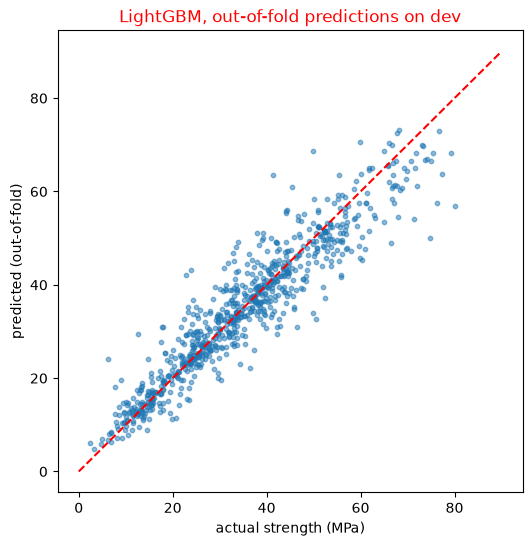

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y, oof, s=10, alpha=0.5)
plt.plot([0, 90], [0, 90], "r--")  # perfect predictions lie on this line
plt.xlabel("actual strength (MPa)")
plt.ylabel("predicted (out-of-fold)")
plt.title("LightGBM, out-of-fold predictions on dev",color='red')
plt.show()

- **Findings (Step 5, error analysis; tuned LightGBM, out-of-fold on dev)**:
    - Overall: RMSE 5.47, MAE 3.85, R2 0.88.
    - Weakest area is strong concrete. True strength above 60 MPa (56 rows): MAE 7.40, bias -6.21 (under-prediction). Low strengths are slightly over-predicted (+1.4 for <= 20 MPa), so predictions are pulled toward the mean. Binning by the TRUE strength exaggerates this (selection effect), but the cement bins agree in direction: 400-600 kg has the worst MAE (5.69) and bias -1.04.
    - Age: MAE is 3.5-4.3 almost everywhere and biases stay within +-1.2. Long ages (90+ days, 107 rows) are not worse than average (MAE 4.14). Worst bin is 56 days (MAE 5.43, RMSE 7.05, 65 rows). Untested hypothesis: slag/fly-ash mixes keep gaining strength after 28 days and are mis-predicted at 56 days. To check with SHAP.
    - Limitation for the README: the model under-predicts high-strength mixes.

## Step 6 - SHAP explanations
- SHAP splits every prediction into a baseline (the model's average output) plus one contribution per feature: prediction = baseline + sum of contributions. Positive means that feature pushed the strength up for that row. Here we fit the final LightGBM on all of dev and explain the dev rows. This is in-sample: it shows what the model learned, not how well it generalizes.

,mean_abs_shap_MPa
age_days,7.30
cement,5.95
water,3.82
slag,2.87
superplasticizer,2.17
fine_agg,1.46
coarse_agg,0.77
fly_ash,0.37


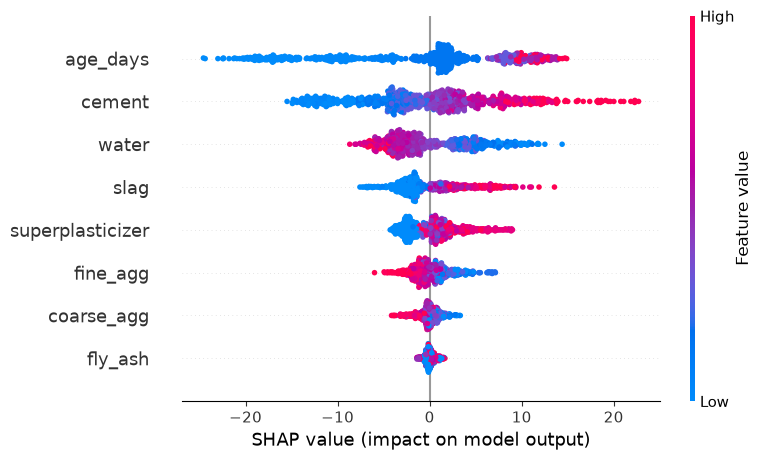

In [11]:
import shap
from src.explain import mean_abs_shap, shap_values

final = build_model("lightgbm", best_params).fit(X8, y)
sv = shap_values(final, X8)
display(mean_abs_shap(sv).round(2).to_frame("mean_abs_shap_MPa"))
shap.summary_plot(sv.values, X8)

In [12]:
# Hypothesis 1 (from EDA): the effect of slag / fly ash depends on age
age_group = pd.cut(X8["age_days"], [0, 7, 28, 365], labels=["<=7d", "8-28d", ">28d"])
for feat in ["slag", "fly_ash"]:
    used = X8[feat] > 0
    print(f"mean SHAP of {feat} by age group, rows where {feat} is used:")
    display(sv.loc[used, feat].groupby(age_group[used], observed=True).agg(["mean", "count"]).round(2))

# Hypothesis 2 (from EDA): superplasticizer acts mostly through lower water
print("corr(water, superplasticizer):", round(X8["water"].corr(X8["superplasticizer"]), 2))

mean SHAP of slag by age group, rows where slag is used:


,mean,count
age_days,,
<=7d,1.29,105
8-28d,3.12,208
>28d,1.98,104


mean SHAP of fly_ash by age group, rows where fly_ash is used:


,mean,count
age_days,,
<=7d,0.15,66
8-28d,0.20,216
>28d,-0.07,94


corr(water, superplasticizer): -0.63
